In [1]:
# 导包
import argparse
import functools
import os
import timeit
from collections import namedtuple

import crypten
import crypten.communicator as comm
import numpy as np
import pandas as pd
import torch

import multiprocess_launcher # 多进程启动器（自编），用于便于使用多进程模拟计算多方

In [1]:
# 全局定义
Runtime = namedtuple("Runtime","mid q1 q3")

In [ ]:
# 基本计时方法
def time_me(func=None,n_loops=10):
    """
    作为装饰器函数用于任何函数上，计算函数的平均运行时间，并返回一个包含运行时间统计信息的对象

    Args:
        func (function): invoked with given args / kwargs（使用给定的args/kwargs调用）
        n_loops (int): number of times to invoke function for timing（调用函数进行计时的次数）

    Returns: 
        tuple of (time in seconds, inner quartile range, function return value).
    """
    if func is None:
        return functools.partial(time_me,n_loops=n_loops)
    
    @functools.wraps(func) # 装饰器，用于将 timing_wrapper 函数的元数据（如名称、文档字符串等）设置为原始函数 func 的元数据，以保留函数的原始信息
    def timing_wrapper(*args,**kwargs):
        return_val = func(*args,**kwargs)
        times = []
        for _ in range(n_loops):
            start = timeit.default_timer()
            func(*args,**kwargs)
            times.append(timeit.default_timer()-start)
        mid_runtime = np.quantile(times,0.5)
        q1_runtime = np.quantile(times,0.25)
        q3_runtime = np.quantile(times,0.75)
        runtime = Runtime(mid_runtime,q1_runtime,q3_runtime)
        return runtime,return_val
    
    return timing_wrapper 

In [ ]:
class FuncBenchmarks:

    ...

    # 函数计时
    @staticmethod
    @time_me
    def time_func(x,func,y=None):
        """
        根据给定的参数调用相应的函数，并测量其运行时间
        getattr(x,func)<=>x.func
        """
        if y is None:
            return getattr(x,func)()
    
        if func in {"conv1d","conv2d"}:
            if torch.is_tensor(x):
                return getattr(torch.nn.functional,func)(x,y)
            return getattr(x,func)(y)
    
        return getattr(x,func)(y) 
    
    ...

    def run():
        ...

In [ ]:
class ModelBenchmarks:

    ...

    # 模型计时
    @time_me(n_loops=3)
    def train(self,model,x,y,epochs,lr,loss):
        """
        PyTorch model
        Args:
            model (PyTorch model): model to be trained
            x (torch.tensor): inputs
            y (torch.tensor): targets
            epochs (int): number of training epochs
            lr (float): learning rate
            loss (str): type of loss to use for training

        Returns:
            model with update weights
        """
        assert isinstance(model,torch.nn.Module),"must be a PyTorch model"
        criterion = getattr(torch.nn,loss)()
        optimizer = torch.optim.SGD(model.parameters(),lr=lr)

        for _ in range(epochs):
            model.zero_grad()
            output = model(x)
            loss = criterion(output,y)
            loss.backward()
            optimizer.step()
    
        return model

    @time_me(n_loops=3)
    def train_crypten(self,model,x,y,epochs,lr,loss):
        """
        crypten model
        Args:
            model (CrypTen model): model to be trained
            x (crypten.tensor): inputs
            y (crypten.tensor): targets
            epochs (int): number of training epochs
            lr (float): learning rate
            loss (str): type of loss to use for training

        Returns:
            model with update weights
        """
        assert isinstance(model,crypten.nn.Module),"must be a CrypTen model"
        criterion = getattr(crypten.nn,loss)()
        # 没有optim

        for _ in range(epochs):
            model.zero_grad()
            output = model(x)
            loss = criterion(output,y)
            loss.backward()
            model.update_parameters(lr)
    
        return model
    
    ...

    @time_me(n_loops=3)
    def predict(self,model,x):
        y = model(x)
        return y
    
    ...

    def run():
        ...

In [ ]:
def multiprocess_caller(args):
    """运行多方基准测试，并从source 0打印/保存"""
    rank = comm.get().get_rank()
    if args.multi_gpu:
        assert (
            args.world_size >= torch.cuda.device_count()
        ), f"Got {args.world_size} parties, but only {torch.cuda.device_count()} GPUs found" # 资源数不够
        device = torch.device(f"cuda:{rank}")
    else:
        device = torch.device(args.device)

    # benchmarks = [
    #     FuncBenchmarks(device=device),
    #     ModelBenchmarks(device=device, advanced_models=args.advanced_models),
    # ]

    if args.only_functions:
        benchmarks = [FuncBenchmarks(device=device)]
    
    for benchmark in benchmarks:
        benchmark.run()
        rank = comm.get().get_rank()
        if rank == 0:
            pd.set_option("display.precision",3)
            print(benchmark)
            if args.path:
                benchmark.save(args.path)
        

In [2]:
import torch
import torch.nn.functional as F

In [8]:
x = torch.tensor([
    [1,1,3],
    [2,3,1],
    [2,1,2000]
],dtype=float)
print(x)
print(x>x.mean()+3*torch.sqrt(x.var()))
print(x.mean()+3*torch.sqrt(x.var())) 

tensor([[1.0000e+00, 1.0000e+00, 3.0000e+00],
        [2.0000e+00, 3.0000e+00, 1.0000e+00],
        [2.0000e+00, 1.0000e+00, 2.0000e+03]], dtype=torch.float64)
tensor([[False, False, False],
        [False, False, False],
        [False, False, False]])
tensor(2222.0293, dtype=torch.float64)


In [13]:
r = torch.tensor([1])
while(1):
    print(86.74+2091+812.8+428.78+526)  
    print()
    i = 1
    i *= 2
    r *= 10
    print(r)
    break

3945.3199999999997
tensor([10])


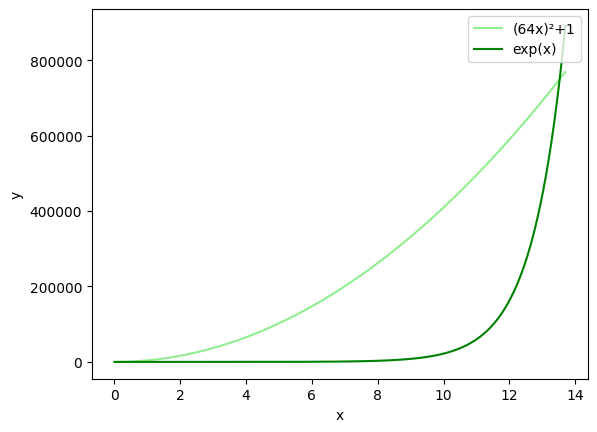

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# 定义x的取值范围
x = np.linspace(0, 13.7, 1000)

# 计算x²和exp(x)的值
y1 = (64**2) * x**2 + 1
y2 = np.exp(x) 
# y3 = 1/(1+np.exp(-x+10))

# 创建一个图形和坐标轴
fig, ax = plt.subplots()

# 绘制x²的图像
ax.plot(x, y1, label='(64x)²+1',color='lightgreen')

# 绘制exp(x)的图像
ax.plot(x, y2, label='exp(x)',color='green')

# 绘制sigmoid(x)的图像
# ax.plot(x, y3, label='sigmoid(x)')

# 设置坐标轴标签
ax.set_xlabel('x')
ax.set_ylabel('y')

# 设置图例位置
ax.legend(loc='upper right')

# 显示图形
plt.show()

-17762.023425125848


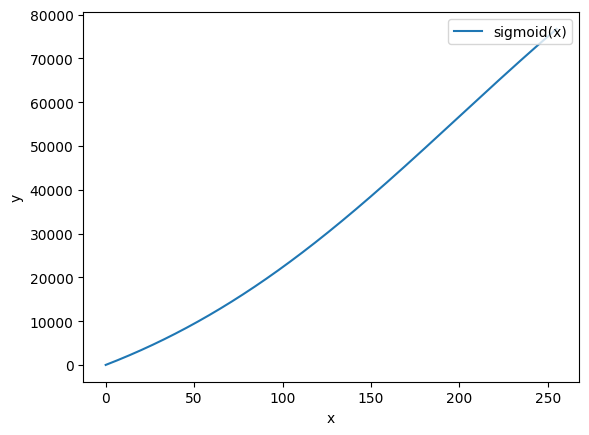

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 定义x的取值范围
x = np.linspace(0,255, 1000)

# 计算x²和exp(x)的值

y3 = 149015/(1+np.exp(-0.01*x+2)) - 17762
b = 1 - 149015/(1+np.exp(2))
print(b)


# 创建一个图形和坐标轴
fig, ax = plt.subplots()

# 绘制sigmoid(x)的图像
ax.plot(x, y3, label='sigmoid(x)')

# 设置坐标轴标签
ax.set_xlabel('x')
ax.set_ylabel('y')

# 设置图例位置
ax.legend(loc='upper right')

# 显示图形
plt.show()

0.9776


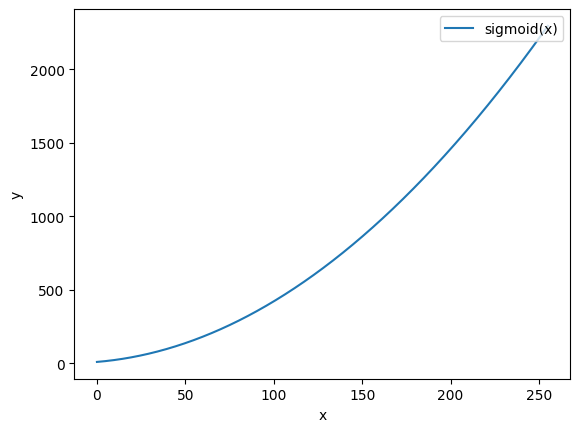

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# 定义x的取值范围
x = np.linspace(0, 255, 1000)

# 计算x²和exp(x)的值

y3 = 0.5*(1-0.25*(x+20))**2 + 1

print(1- 0.14*(1-0.07*abs(20))**2)

# 创建一个图形和坐标轴
fig, ax = plt.subplots()

# 绘制sigmoid(x)的图像
ax.plot(x, y3, label='sigmoid(x)')

# 设置坐标轴标签
ax.set_xlabel('x')
ax.set_ylabel('y')

# 设置图例位置
ax.legend(loc='upper right')

# 显示图形
plt.show()

In [ ]:
import torch

def custom_fold(unfolded_input, output_size, kernel_size, stride):
    # 获取展开后的数据形状
    batches, channels_times_k2, num_windows = unfolded_input.size()

    # 计算输出的高度和宽度
    output_height, output_width = output_size

    # 计算输入的高度和宽度
    input_height = (output_height - 1) * stride + kernel_size
    input_width = (output_width - 1) * stride + kernel_size

    # 初始化一个空的张量来存储折叠后的数据
    folded_input = torch.zeros(batches, channels_times_k2 // (kernel_size**2), input_height, input_width)

    # 对每个滑动窗口进行折叠
    for i in range(num_windows):
        window = unfolded_input[:, :, i].contiguous()
        window = window.view(batches, -1, kernel_size, kernel_size)
        start_h = (i // output_width) * stride
        start_w = (i % output_width) * stride
        end_h = start_h + kernel_size
        end_w = start_w + kernel_size
        folded_input[:, :, start_h:end_h, start_w:end_w] += window

    return folded_input[:, :, :output_height, :output_width]

def custom_unfold(data_input, kernel_size, stride):
    # 获取输入数据的形状
    batches, channels, height, width = data_input.size()

    # 计算池化后的高度和宽度
    pooled_height = (height - kernel_size) // stride + 1
    pooled_width = (width - kernel_size) // stride + 1

    # 初始化一个空的张量来存储展开后的数据
    unfolded_input = torch.zeros(batches, channels * kernel_size**2, pooled_height * pooled_width)

    # 对每个滑动窗口进行展开
    for i in range(pooled_height):
        for j in range(pooled_width):
            start_h = i * stride
            start_w = j * stride
            end_h = start_h + kernel_size
            end_w = start_w + kernel_size
            window = data_input[:, :, start_h:end_h, start_w:end_w].contiguous()
            window = window.view(batches, -1, 1)
            unfolded_input[:, :, i * pooled_width + j] = window.squeeze()

    return unfolded_input

def soft_pool2d_backward(diff_output, data_input, kernel_size, stride):
    # 获取输入数据的形状
    batches, channels, height, width = data_input.size()

    # 计算池化后的高度和宽度
    pooled_height = height // stride
    pooled_width = width // stride

    # 展开输入数据
    unfolded_input = custom_unfold(data_input, kernel_size, stride)

    # 将展开后的输入数据重塑为合适的形状
    unfolded_input = unfolded_input.view(batches, channels, kernel_size**2, pooled_height * pooled_width)

    # 计算每个核区域内的指数项和
    mask_sum_max = torch.exp(unfolded_input).sum(dim=2)

    # 对 mask_sum_max 进行截断，确保其在一定范围内
    mask_sum_max = torch.clamp(mask_sum_max, float('-inf'), float('inf'))

    # 计算梯度并更新到输入梯度中
    diff_input = torch.exp(data_input) / mask_sum_max.unsqueeze(2)
    diff_input = (diff_output.unsqueeze(2) * diff_input).view(batches, channels, kernel_size**2, pooled_height * pooled_width)
    diff_input = custom_fold(diff_input, (height, width), kernel_size, stride)

    return diff_input

In [268]:
import numpy as np
import torch

epsilon = np.random.laplace(0, 1e-4) # 随机噪声
print(epsilon)

-5.5009335082226846e-05


In [1]:
import torch

In [2]:
x = torch.tensor([841])

print(torch.sqrt(x))

tensor([29.])


In [1]:
import torch

In [8]:
x = torch.rand(size=(3,3,10,10))
print(x[:,:,0:2,0:2].shape)

torch.Size([3, 3, 2, 2])


In [5]:
dict = {"1":21,"2":22,"3":23,"4":24,"5":25,"6":26,"7":27}
for i,(input,target) in enumerate(dict):
    print(i)


ValueError: not enough values to unpack (expected 2, got 1)

In [1]:
import torch

In [315]:
var = torch.tensor([2.0])
C=6
xita = torch.tensor([2.0])
for i in range(4):
    xita = xita * (((C+1) - (var+0.001)*xita.square())/C)
print(xita)
print(1/var.sqrt())

tensor([-0.4682])
tensor([0.7071])


In [1]:
import torch

In [31]:
a = [
    [2,3,2,1,4,2],
    [1,5,8,8,9,1],
    [1,2,3,4,9,8],
    [2,8,3,8,4,2],
    [2,4,9,3,4,1],
    [1,4,5,2,1,1]
]
a = torch.tensor(a,dtype=torch.float32)
miu = a.mean()
var = a.var()
print(miu)
print(var)
r = 7*miu*miu + 9*var
print("r:",r)

s = 0
for i in range(2,5):
    for j in range(2,5):
        y = (64**2*a[i][j]**2)/r + 1/r
        s += y
print(s)
sw = 0
for i in range(2,5):
    for j in range(2,5):
        y = (64**2*a[i][j]**2)/r + 1/r
        w = y / s
        sw += w
        print(a[i][j]," w:",w)
print(sw)
        

tensor(3.8056)
tensor(7.5325)
r: tensor(169.1686)
tensor(7288.0229)
tensor(3.)  w: tensor(0.0299)
tensor(4.)  w: tensor(0.0532)
tensor(9.)  w: tensor(0.2691)
tensor(3.)  w: tensor(0.0299)
tensor(8.)  w: tensor(0.2126)
tensor(4.)  w: tensor(0.0532)
tensor(9.)  w: tensor(0.2691)
tensor(3.)  w: tensor(0.0299)
tensor(4.)  w: tensor(0.0532)
tensor(1.0000)


In [30]:
a = [
    [0.2,0.3,0.2,0.1,0.4,0.2],
    [0.1,0.5,0.8,0.8,0.9,0.1],
    [0.1,0.2,0.3,0.4,0.9,0.8],
    [0.2,0.8,0.3,0.8,0.4,0.2],
    [0.2,0.4,0.9,0.3,0.4,0.1],
    [0.1,0.4,0.5,0.2,0.1,0.1]
]
a = torch.tensor(a,dtype=torch.float32)
miu = a.mean()
var = a.var()
print(miu)
print(var)
r = 7*miu*miu + 9*var
print("r:",r)

s = 0
for i in range(2,5):
    for j in range(2,5):
        y = (64**2*a[i][j]**2)/r + 1/r
        s += y
print(s)
sw = 0
for i in range(2,5):
    for j in range(2,5):
        y = (64**2*a[i][j]**2)/r + 1/r
        w = y / s
        sw += w
        print(a[i][j]," w:",w)
print(sw)
        

tensor(0.3806)
tensor(0.0753)
r: tensor(1.6917)
tensor(7293.2915)
tensor(0.3000)  w: tensor(0.0300)
tensor(0.4000)  w: tensor(0.0532)
tensor(0.9000)  w: tensor(0.2690)
tensor(0.3000)  w: tensor(0.0300)
tensor(0.8000)  w: tensor(0.2126)
tensor(0.4000)  w: tensor(0.0532)
tensor(0.9000)  w: tensor(0.2690)
tensor(0.3000)  w: tensor(0.0300)
tensor(0.4000)  w: tensor(0.0532)
tensor(1.0000)


In [7]:
def count_perfect_submatrices(matrix, i):
    rows = len(matrix)
    cols = len(matrix[0])
    dp = [[0] * (cols+1) for _ in range(rows+1)]
    count = 0

    for r in range(1, rows+1):
        for c in range(1, cols+1):
            if matrix[r-1][c-1] == 1:
                dp[r][c] = min(dp[r-1][c], dp[r][c-1], dp[r-1][c-1]) + 1
                if dp[r][c] >= i:
                    count += 1
    
    return count

# 示例矩阵
matrix = [
    [0, 1, 0, 1],
    [1, 0, 1, 0],
    [0, 1, 0, 1],
    [1, 0, 1, 0]
]

i = 2
result = count_perfect_submatrices(matrix, i)
print(result)


0


In [8]:
import numpy as np

x1 = 3
x2 = 2

r = max(x1,x2)
a = np.exp(x1-r) / np.exp(x2-r)
x1 = x1 / r
x2 = x2 / r
print(x1)
print(x2)

b = (1*x1**2) / (1*x2**2)
print(a)
print(b)

1.0
0.6666666666666666
2.718281828459045
2.25


In [ ]:
/data2/ljd/home/SICM/data/img/images/packages